# Azure PTU Batch Accelerator
### A presenter walkthrough using the official OpenAI Python SDK

**Story:** keep the familiar Files + Batch workflow and send asynchronous requests to capacity the customer already owns.

This notebook targets your deployed Azure accelerator. It never uses local echo, canned model responses, or a Standard inference fallback.

> **Default mode:** Part A demonstrates the real deployed platform without model inference. Part B contains the full PTU workflow and stays disabled until an existing PTU is configured and admission is resumed.

**Suggested presentation:** architecture → client configuration → authentication → JSONL upload and integrity → Batch API guard → optional real PTU batch → correlated output.

## 1. Explain the architecture

The API stores inputs and job state. Cosmos change feed and Service Bus drive the control and inference Functions. The inference worker calls the existing PTU deployment and commits results before the batch is finalized.

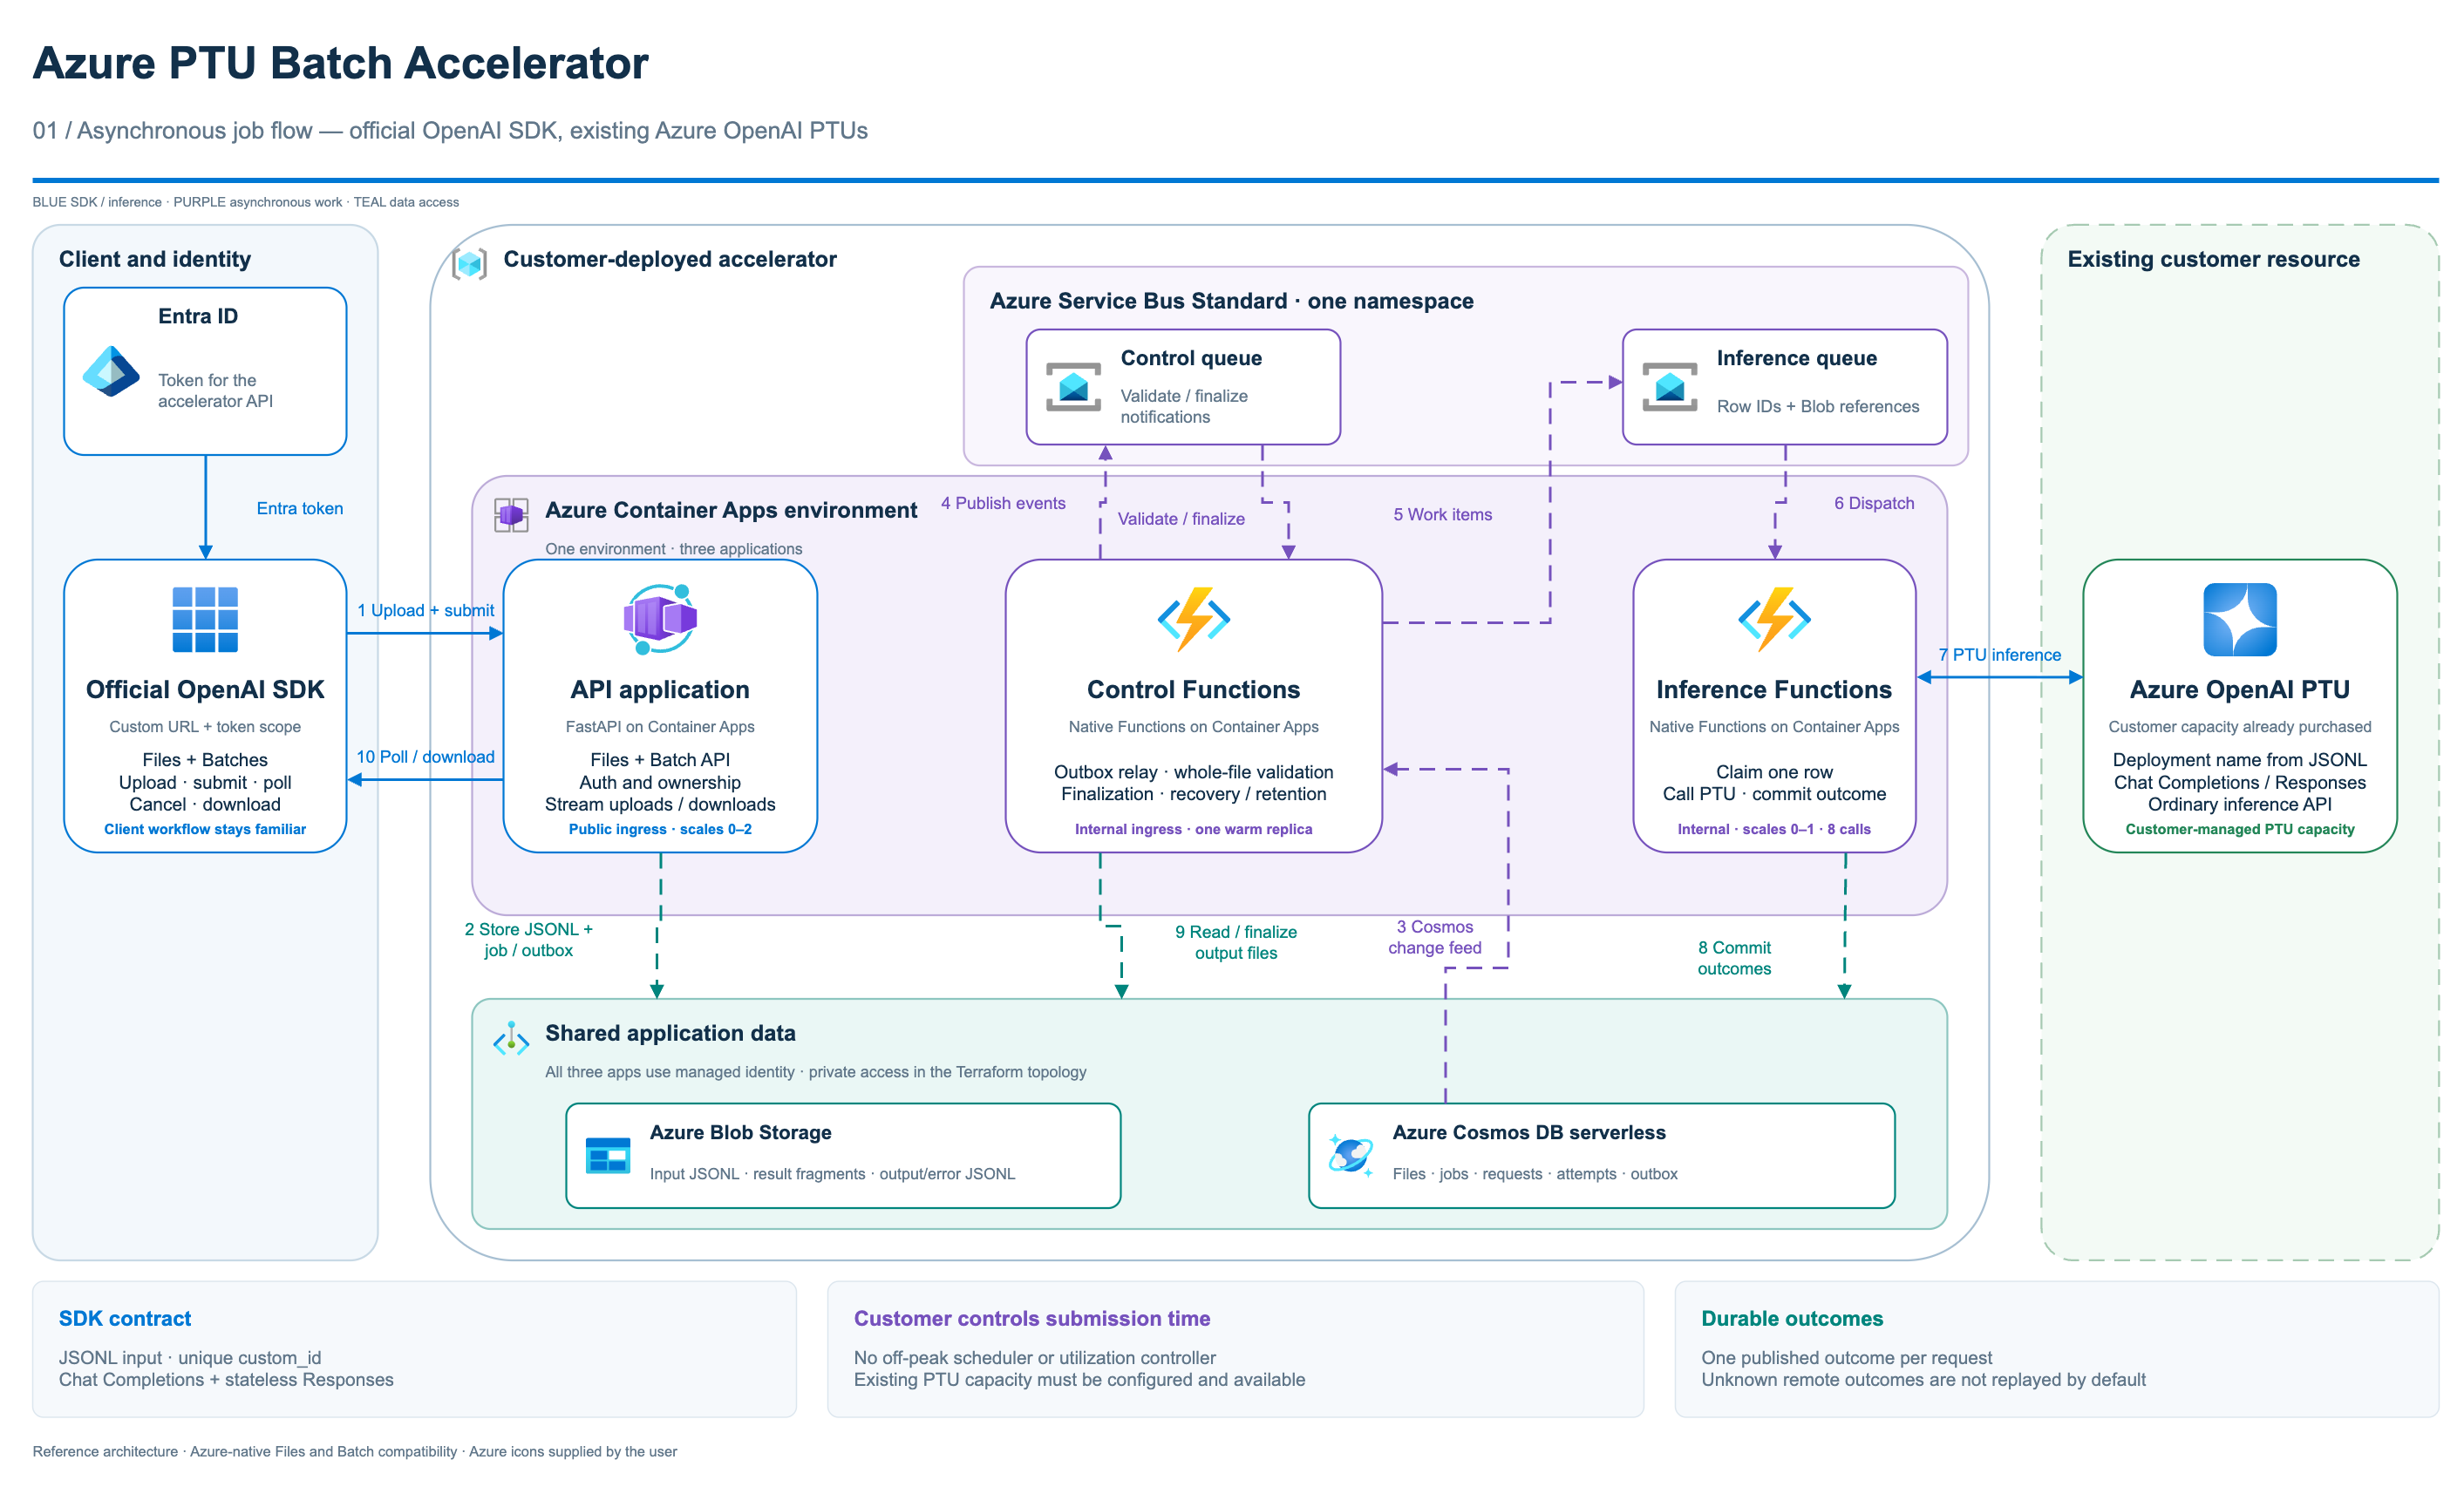

**Say:** “The customer changes the client URL and token scope; the familiar SDK file and batch calls stay the same.”

## 2. Open the notebook locally

Use **VS Code with the Jupyter extension**, or JupyterLab, with a Python 3.12 kernel. Azure CLI must be installed and signed into the tenant used below.

If imports fail, uncomment and run the `%pip` line in the next cell, then restart the kernel. Sign in from a terminal if required:

```bash
az login --tenant YOUR-TENANT-ID
```

Your account/client also needs the delegated `Batch.ReadWrite` permission and consent for this API; signing in alone does not grant it. An operator can preauthorize Azure CLI for the demo or arrange the required delegated consent. The notebook verifies permission with an authenticated Files request before uploading data.

The notebook obtains an Entra token when the SDK makes a request. Tokens and authorization headers are never printed or saved.

In [ ]:
# Uncomment only when the selected kernel needs these packages:
# %pip install "openai==3.42.1" "azure-identity==1.27.0" "httpx==0.28.1"

import html
import importlib.metadata
import json
import os
import tempfile
import time
import uuid
from datetime import UTC, datetime
from pathlib import Path
from urllib.parse import urlparse

import httpx
from azure.identity import AzureCliCredential, get_bearer_token_provider
from IPython.display import HTML, Markdown, display
from openai import APIStatusError, OpenAI

print(
    "SDK versions:",
    {name: importlib.metadata.version(name) for name in ("openai", "azure-identity", "httpx")},
)

In [ ]:
# Preconfigured for your deployed accelerator. These identifiers are not secrets.
BASE_URL = os.getenv(
    "PTU_BATCH_BASE_URL", "https://YOUR-ACCELERATOR.eastus.azurecontainerapps.io/openai/v1/"
)
TENANT_ID = os.getenv("PTU_BATCH_TENANT_ID", "YOUR-TENANT-ID")
API_APP_ID = os.getenv("PTU_BATCH_APP_ID", "YOUR-API-APP-ID")
# Optional: upload an existing JSONL file unchanged, including each body.model.
INPUT_JSONL_PATH = os.getenv("PTU_BATCH_INPUT_JSONL", "")

# Keep both defaults unchanged for the currently deployed validation environment.
ENVIRONMENT_IS_VALIDATION_ONLY = True
RUN_REAL_PTU_BATCH = False

# Choose "chat" or "responses" after checking the configured deployment's capabilities.
REQUEST_API = "chat"
POLL_SECONDS = 2
PRESENTATION_WAIT_SECONDS = 180
RUN_ADMISSION_PROBE = True
CLEAN_UP_DEMO_FILES = True

parsed = urlparse(BASE_URL)
if parsed.scheme != "https" or parsed.path.rstrip("/") != "/openai/v1":
    raise ValueError("Use the accelerator HTTPS base URL ending in /openai/v1/.")
if REQUEST_API not in {"chat", "responses"}:
    raise ValueError("REQUEST_API must be chat or responses.")
if RUN_REAL_PTU_BATCH and ENVIRONMENT_IS_VALIDATION_ONLY:
    raise RuntimeError("A real PTU must be configured and validation-only mode disabled first.")

ORIGIN = f"{parsed.scheme}://{parsed.netloc}"
TOKEN_SCOPE = f"api://{API_APP_ID}/.default"
RUN_ID = uuid.uuid4().hex[:8]
WORK_DIR = Path(tempfile.mkdtemp(prefix="ptu-batch-demo-"))
WORK_DIR.chmod(0o700)


def save_private(path, data):
    raw = data.encode("utf-8") if isinstance(data, str) else data
    descriptor = os.open(path, os.O_CREAT | os.O_WRONLY | os.O_TRUNC, 0o600)
    with os.fdopen(descriptor, "wb") as stream:
        stream.write(raw)
    path.chmod(0o600)


created_file_ids = []
batch = None
probe_batch = None
rows = []
outputs = []
errors = []
checks = {}

In [ ]:
def notice(title, message, tone="blue"):
    colors = {
        "blue": ("#eaf4ff", "#0078d4"),
        "green": ("#eaf7ed", "#207340"),
        "amber": ("#fff5df", "#8a5a00"),
        "red": ("#ffeded", "#b42318"),
    }
    bg, accent = colors[tone]
    display(
        HTML(
            f'<div style="font-family:Arial;padding:16px 20px;margin:12px 0;'
            f'border-left:5px solid {accent};background:{bg};border-radius:8px;">'
            f'<b style="color:{accent}">{html.escape(title)}</b><br>'
            f"{html.escape(message)}</div>"
        )
    )


def table(records):
    records = list(records)
    if not records:
        display(Markdown("_No rows._"))
        return
    keys = list(records[0])
    head = "".join(
        f'<th style="padding:8px;text-align:left;border-bottom:2px solid #0078d4">'
        f"{html.escape(str(key))}</th>"
        for key in keys
    )
    body = "".join(
        "<tr>"
        + "".join(
            f'<td style="padding:8px;vertical-align:top;border-bottom:1px solid #dde7ef;white-space:pre-wrap">'
            f"{html.escape(str(row.get(key, '')))}</td>"
            for key in keys
        )
        + "</tr>"
        for row in records
    )
    display(
        HTML(
            f'<table style="font-family:Arial;font-size:14px;width:100%;border-collapse:collapse">'
            f"<thead>{head}</thead><tbody>{body}</tbody></table>"
        )
    )


def batch_summary(value):
    counts = value.request_counts
    return {
        "batch_id": value.id,
        "status": value.status,
        "total": counts.total,
        "completed": counts.completed,
        "failed": counts.failed,
        "output_file_id": value.output_file_id or "—",
        "error_file_id": value.error_file_id or "—",
    }


notice(
    "Live Azure platform demo",
    "Full model execution is disabled. Authentication, Files, and the admission guard use the deployed service.",
    "amber",
)
table(
    [
        {"Setting": "Endpoint", "Value": BASE_URL},
        {"Setting": "Authentication", "Value": "Microsoft Entra ID; accelerator API scope"},
        {
            "Setting": "Mode",
            "Value": "Validation only" if ENVIRONMENT_IS_VALIDATION_ONLY else "PTU configured",
        },
        {"Setting": "Request API", "Value": REQUEST_API},
    ]
)

## 3. Show health and the authentication boundary

The health route is public for infrastructure checks. The Files API requires a valid accelerator token. A cold API replica can take a little time to wake up.

In [ ]:
health = httpx.get(f"{ORIGIN}/healthz", timeout=90)
health.raise_for_status()
anonymous = httpx.get(f"{BASE_URL}files", timeout=90)
assert health.json()["status"] == "ok"
assert anonymous.status_code == 401
checks["Public health"] = "200 OK"
checks["Anonymous access rejected"] = "401 Unauthorized"
table(
    [
        {"Check": "Public health", "HTTP": health.status_code},
        {"Check": "Files without a token", "HTTP": anonymous.status_code},
    ]
)

## 4. Configure the official OpenAI client

The `base_url` points to the accelerator. The token provider requests the accelerator API audience rather than an Azure OpenAI resource audience. Explicit tenant selection avoids using the Azure CLI's unrelated default tenant.

In [ ]:
credential = AzureCliCredential(tenant_id=TENANT_ID, process_timeout=60)
token_provider = get_bearer_token_provider(credential, TOKEN_SCOPE)

client = OpenAI(
    base_url=BASE_URL,
    api_key=token_provider,
    max_retries=0,
    timeout=90,
)

recent_files = client.files.list(limit=5)
checks["Authenticated SDK request"] = "Accepted"
notice(
    "Authenticated SDK connected",
    f"Files API accepted the Entra token. Returned {len(recent_files.data)} recent file(s).",
    "green",
)

## 5. Prepare a small customer scenario

Classify three support tickets. Each JSONL row has a unique `custom_id`, one normalized endpoint, and the actual Azure PTU deployment name in `body.model`.

**Say:** “Every result comes back with the caller's custom ID. Input and output order do not need to match.”

Edit `body.model` in the sample below, or set `INPUT_JSONL_PATH` in cell 2 to your existing `chat.jsonl`. The file is uploaded unchanged; no deployment alias or deployment name needs registering on the server. Use one deployment per file.

In [ ]:
rows = []  # Re-running this cell rebuilds the input rather than appending duplicates.
tickets = [
    {"custom_id": "billing-001", "text": "I was charged twice for this month's subscription."},
    {"custom_id": "access-002", "text": "I cannot sign in after changing my MFA device."},
    {"custom_id": "howto-003", "text": "How can I export last month's invoice as a PDF?"},
]
instruction = (
    "Classify the support ticket. Return a JSON object with category "
    "(billing, access, or howto), priority (low, medium, or high), and a short summary. "
    "Use only the supplied ticket; do not invent customer details."
)
ENDPOINT = "/chat/completions" if REQUEST_API == "chat" else "/responses"
for ticket in tickets:
    if REQUEST_API == "chat":
        body = {
            "model": "REPLACE-WITH-MODEL-DEPLOYMENT-NAME",
            "messages": [
                {"role": "system", "content": instruction},
                {"role": "user", "content": ticket["text"]},
            ],
            "max_completion_tokens": 160,
        }
    else:
        body = {
            "model": "REPLACE-WITH-MODEL-DEPLOYMENT-NAME",
            "instructions": instruction,
            "input": ticket["text"],
            "max_output_tokens": 160,
            "store": False,
        }
    rows.append(
        {"custom_id": ticket["custom_id"], "method": "POST", "url": "/v1" + ENDPOINT, "body": body}
    )
if INPUT_JSONL_PATH:
    input_path = Path(INPUT_JSONL_PATH).expanduser()
    input_bytes = input_path.read_bytes()
    rows = [json.loads(line) for line in input_bytes.decode("utf-8").splitlines() if line.strip()]
else:
    input_bytes = b"".join(
        (json.dumps(row, ensure_ascii=False) + "\n").encode("utf-8") for row in rows
    )
    input_path = WORK_DIR / f"tickets-{REQUEST_API}.jsonl"
    save_private(input_path, input_bytes)
assert rows and len({row["custom_id"] for row in rows}) == len(rows)
if RUN_REAL_PTU_BATCH and any(
    str(row.get("body", {}).get("model", "")).startswith("REPLACE-") for row in rows
):
    raise ValueError("Set body.model in your JSONL to the actual Azure PTU deployment name.")
table(
    [
        {"custom_id": row["custom_id"], "model": row.get("body", {}).get("model")}
        for row in rows[:10]
    ]
)
print("JSONL bytes:", len(input_bytes), "| requests:", len(rows))
print("\n".join(input_bytes.decode("utf-8").splitlines()[:3]))

## 6. Upload, retrieve, and download the input

These are real SDK Files calls against Azure-backed Blob Storage and Cosmos DB. Uploading the input file does not run inference.

In [ ]:
uploaded = client.files.create(
    file=(input_path.name, input_bytes),
    purpose="batch",
    extra_body={"expires_after": {"anchor": "created_at", "seconds": 1209600}},
)
created_file_ids.append(uploaded.id)
retrieved = client.files.retrieve(uploaded.id)
downloaded_input = client.files.content(uploaded.id).read()
assert retrieved.id == uploaded.id and downloaded_input == input_bytes
checks["Files upload / retrieve / content"] = "Passed; bytes match"
table(
    [
        {
            "file_id": uploaded.id,
            "purpose": uploaded.purpose,
            "bytes": uploaded.bytes,
            "status": uploaded.status,
        }
    ]
)
notice(
    "Input persisted and verified",
    "The downloaded content exactly matches the uploaded JSONL.",
    "green",
)

## 7. List batches and demonstrate paused admission

Listing is available while admission is paused. The optional admission check uploads a deliberately invalid **GET** row. If admission is paused, creation returns the expected 503. If admission has been opened, the invalid row is rejected by whole-file validation before it can call a model. This notebook does not resume or otherwise change admission.

Historical failed rows in the batch list are platform validation probes, not completed model jobs.

In [ ]:
recent_batches = client.batches.list(limit=5)
table([batch_summary(item) for item in recent_batches.data])
checks["Batch listing"] = "Passed"

In [ ]:
if RUN_ADMISSION_PROBE and not RUN_REAL_PTU_BATCH:
    invalid_row = {**rows[0], "custom_id": f"admission-probe-{RUN_ID}", "method": "GET"}
    invalid_bytes = (json.dumps(invalid_row) + "\n").encode("utf-8")
    probe_file = client.files.create(
        file=("invalid-admission-probe.jsonl", invalid_bytes),
        purpose="batch",
        extra_body={"expires_after": {"anchor": "created_at", "seconds": 1209600}},
    )
    created_file_ids.append(probe_file.id)
    try:
        probe_batch = client.batches.create(
            input_file_id=probe_file.id,
            endpoint=ENDPOINT,
            completion_window="24h",
            metadata={"source": "notebook-admission-probe"},
        )
    except APIStatusError as exc:
        if exc.status_code != 503:
            raise
        checks["Paused admission"] = "503 returned as expected; no batch accepted"
        notice(
            "Admission guard verified",
            "The Files API works while new batch submissions are paused. No inference was dispatched.",
            "green",
        )
    else:
        deadline = time.monotonic() + 180
        while (
            probe_batch.status not in {"failed", "completed", "cancelled", "expired"}
            and time.monotonic() < deadline
        ):
            time.sleep(POLL_SECONDS)
            probe_batch = client.batches.retrieve(probe_batch.id)
        if probe_batch.status == "failed":
            details = probe_batch.errors.model_dump() if probe_batch.errors else {}
            assert any(item.get("param") == "method" for item in details.get("data", []))
            checks["Whole-file validation"] = "Invalid method rejected before inference"
            notice(
                "Admission was open",
                "The deliberately invalid GET row failed validation before model dispatch. Admission was not changed by this notebook.",
                "amber",
            )
        else:
            raise RuntimeError(
                f"Validation probe has status {probe_batch.status}; inspect it before cleanup."
            )
else:
    display(Markdown("_Admission probe skipped._"))

## Part B — full PTU batch workflow

This section is ready for an existing PTU deployment. Before enabling it, the operator must configure the trusted Azure OpenAI account once and put the actual PTU deployment name in the JSONL file, disable Terraform validation-only mode, pass PTU/API/spillover preflight, and resume submission admission. The runtime validates that chosen deployment is provisioned, ready, API-compatible and has no Standard spillover before dispatch. Then set both controls in cell 2:

```python
ENVIRONMENT_IS_VALIDATION_ONLY = False
RUN_REAL_PTU_BATCH = True
```

Running the remaining cells with today's defaults skips model execution. A successful Files demonstration is not proof of PTU inference or savings. Request-body parameters may need adjusting to the selected model.

## 8. Submit the real batch

**Say:** “The create call returns immediately. The service validates the whole file before it dispatches any request.”

`24h` is the accepted completion-window target; it is not a guaranteed completion SLA.

In [ ]:
if RUN_REAL_PTU_BATCH:
    if ENVIRONMENT_IS_VALIDATION_ONLY:
        raise RuntimeError("Real inference is disabled for this validation-only environment.")
    batch = client.batches.create(
        input_file_id=uploaded.id,
        endpoint=ENDPOINT,
        completion_window="24h",
        metadata={"source": "jupyter-showcase", "run": RUN_ID},
        extra_body={"output_expires_after": {"anchor": "created_at", "seconds": 1209600}},
    )
    table([batch_summary(batch)])
else:
    notice(
        "Real PTU batch not submitted",
        "Configure an existing PTU and enable the two settings above when you are ready for full inference.",
        "amber",
    )

## 9. Poll status and request counts

The presentation wait is bounded. If it expires, the accepted job continues in Azure; rerun this cell to keep polling. The notebook does not automatically retry submission or cancel a running batch.

In [ ]:
status_history = []
if batch is not None:
    handle = display(HTML("<p>Polling the batch…</p>"), display_id=True)
    deadline = time.monotonic() + PRESENTATION_WAIT_SECONDS
    while True:
        batch = client.batches.retrieve(batch.id)
        summary = batch_summary(batch)
        if not status_history or status_history[-1]["status"] != batch.status:
            status_history.append(
                {
                    "time_utc": datetime.now(UTC).isoformat(timespec="seconds"),
                    "status": batch.status,
                }
            )
        handle.update(HTML("<pre>" + html.escape(json.dumps(summary, indent=2)) + "</pre>"))
        if (
            batch.status in {"completed", "failed", "cancelled", "expired"}
            or time.monotonic() >= deadline
        ):
            break
        time.sleep(POLL_SECONDS)
    table(status_history)
    checks["Real batch status"] = batch.status
    if batch.errors:
        print(json.dumps(batch.errors.model_dump(), indent=2))
    if batch.status not in {"completed", "failed", "cancelled", "expired"}:
        notice(
            "Job still running",
            "The job remains active in Azure. Rerun this cell to continue observing it.",
            "blue",
        )
else:
    display(Markdown("_Polling skipped: no real batch was submitted._"))

## 10. Download output and error JSONL

The same Files API downloads the final artifacts. Output order can differ from input order, so the next step correlates records by `custom_id`.

In [ ]:
if batch is not None and batch.status in {"completed", "cancelled", "expired", "failed"}:
    if batch.output_file_id:
        output_text = client.files.content(batch.output_file_id).text
        save_private(WORK_DIR / "batch-output.jsonl", output_text)
        outputs = [json.loads(line) for line in output_text.splitlines() if line.strip()]
        print(f"Downloaded {len(outputs)} output record(s).")
    if batch.error_file_id:
        error_text = client.files.content(batch.error_file_id).text
        save_private(WORK_DIR / "batch-errors.jsonl", error_text)
        errors = [json.loads(line) for line in error_text.splitlines() if line.strip()]
        print(f"Downloaded {len(errors)} error record(s).")
    if not batch.output_file_id and not batch.error_file_id:
        notice(
            "No result artifacts",
            "Whole-file validation failures are shown in batch.errors rather than a model output file.",
            "amber",
        )
else:
    display(Markdown("_Result download skipped: no terminal real batch is available._"))

In [ ]:
def response_text(body):
    if body.get("choices"):
        return body["choices"][0].get("message", {}).get("content", "")
    return "\n".join(
        part.get("text", "")
        for item in body.get("output", [])
        for part in item.get("content", [])
        if part.get("type") == "output_text"
    )


if outputs or errors:
    expected = {row["custom_id"] for row in rows}
    all_records = outputs + errors
    ids = [row["custom_id"] for row in all_records]
    assert len(ids) == len(set(ids)) and set(ids) <= expected
    if batch.status == "completed":
        assert set(ids) == expected, "A completed batch must correlate every input."
    input_by_id = {row["custom_id"]: json.dumps(row["body"], ensure_ascii=False) for row in rows}
    table(
        [
            {
                "custom_id": row["custom_id"],
                "input": input_by_id[row["custom_id"]],
                "HTTP": (row.get("response") or {}).get("status_code", "error"),
                "result": response_text((row.get("response") or {}).get("body", {}))
                or json.dumps(row.get("error")),
            }
            for row in all_records
        ]
    )
    checks["Output correlation"] = f"{len(ids)} unique custom IDs matched"
else:
    display(Markdown("_No model results were generated or fabricated in this run._"))

## 11. Optional cancellation

Cancellation stops undispatched work and publishes available partial results after its bounded drain interval. It cannot undo a model request already dispatched. This cell only targets the real batch created by this notebook.

In [ ]:
CANCEL_THIS_DEMO_BATCH = False
if (
    CANCEL_THIS_DEMO_BATCH
    and batch is not None
    and batch.status not in {"completed", "failed", "cancelled", "expired"}
):
    batch = client.batches.cancel(batch.id)
    table([batch_summary(batch)])
else:
    display(Markdown("_Cancellation not requested._"))

## 12. Show what was actually demonstrated

Use this table to separate platform/API evidence from model inference. This notebook never estimates cost savings from an empty or validation-only run.

In [ ]:
checks["Model execution requested"] = (
    "Yes: operator-enabled PTU path" if RUN_REAL_PTU_BATCH else "No"
)
checks["Model results downloaded"] = len(outputs)
table([{"Evidence": key, "Observed": value} for key, value in checks.items()])
if not RUN_REAL_PTU_BATCH:
    notice(
        "Platform demo complete",
        "Live authentication, Files, batch listing, and admission checks completed. Full PTU inference remains disabled.",
        "green",
    )

## 13. Cleanup and close

Only input/probe files created by this notebook run are eligible for deletion. If its batch is still active, keep its input pinned. Final output/error files retain their configured expiration and are left available for follow-up review. Local JSONL artifacts use a private temporary directory and file permissions. The included sample data is generic; clear outputs before sharing a notebook that you later run on sensitive customer data.

In [ ]:
active_input = (
    uploaded.id
    if batch is not None and batch.status not in {"completed", "failed", "cancelled", "expired"}
    else None
)
active_probe_input = (
    probe_batch.input_file_id
    if probe_batch is not None
    and probe_batch.status not in {"completed", "failed", "cancelled", "expired"}
    else None
)
if CLEAN_UP_DEMO_FILES:
    cleanup = []
    for file_id in dict.fromkeys(created_file_ids):
        if file_id in {active_input, active_probe_input}:
            cleanup.append({"file_id": file_id, "cleanup": "Retained: active batch input"})
            continue
        result = client.files.delete(file_id)
        cleanup.append(
            {"file_id": file_id, "cleanup": "Deleted" if result.deleted else "Not deleted"}
        )
    table(cleanup)
client.close()
credential.close()
print("Client resources closed. This notebook did not modify server admission settings.")

## Presenter close

- **Same SDK workflow:** upload → create batch → poll → download.
- **Different execution target:** ordinary inference on a configured existing Azure OpenAI PTU.
- **Durable Azure services:** Blob, Cosmos DB, Service Bus, native Functions on Container Apps.
- **Customer controls timing:** no off-peak scheduler or utilization controller.
- **Clear delivery semantics:** at most one published outcome; unknown remote outcomes are not replayed by default.

For this environment, configure a real PTU before presenting successful inference or token/cost savings. The platform is deployed; it is not a substitute for provisioning a PTU.

[Project and architecture](https://github.com/monuminu/azure-ptu-batch-accelerator#architecture) · [Deployment guide](https://github.com/monuminu/azure-ptu-batch-accelerator/blob/main/docs/terraform-deployment.md) · [Azure Batch SDK tutorial](https://learn.microsoft.com/azure/foundry/openai/how-to/batch?pivots=programming-language-python) · [OpenAI output correlation](https://developers.openai.com/api/docs/guides/batch#5-retrieve-the-results)